In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [3]:
class MassEncoding(nn.Module):
	def __init__(self, resolution):
		super().__init__()
		self.a = nn.Parameter(torch.randn(1, resolution))
		self.b = nn.Parameter(torch.randn(1, resolution))
		self.c = nn.Parameter(torch.randn(1, resolution) / resolution)

	def forward(self, x, derivative=0):
		z = self.a * x - self.b
		if derivative % 4 == 0:
			y = torch.sin(z)
		elif derivative % 4 == 1:
			y = torch.cos(z)
		elif derivative % 4 == 2:
			y = -torch.sin(z)
		else:
			y = -torch.cos(z)
		return (self.c * self.a.pow(derivative) * y).sum(dim=-1, keepdim=True)

	def compose(self, x, k):
		fix = [self(x)]
		dfix = [self(x, 1)]
		for _ in range(k - 1):
			fix.append(self(fix[-1]))
			dfix.append(self(fix[-1], 1) * dfix[-1])
		return torch.stack(fix), torch.stack(dfix)

In [4]:
mse_loss = nn.MSELoss()

def loss_fn(f, x):
	fx = f(x)
	dfx = f(x, 1)
	return mse_loss(fx, dfx)

# def loss_fn(f, x, k):
#     _, dfx = f.compose(x, k)
#     return mse_loss(dfx[1:], 1.2 * dfx[:-1] + 0.5)

In [5]:
best_device = "cuda" if torch.cuda.is_available() else "cpu"
force_cpu = False
device = best_device if not force_cpu else "cpu"
best_device, device

('cuda', 'cuda')

In [ ]:
num_epochs = 100_000
batch_size = 64
resolution = 64
domain = (0, 5)
size_norm = 1.0
size_norm_weight = 0.001
torch.manual_seed(40)

f = MassEncoding(resolution)
f.to(device)
optimizer = torch.optim.Adam(f.parameters(), lr=1e-3)

for i in range(num_epochs):
    x = torch.rand(batch_size, 1, device=device) * (domain[1] - domain[0]) + domain[0]

    size = f(x).abs().mean()
    size_loss = size_norm_weight * (size - size_norm)**2
    target_loss = loss_fn(f, x)

    optimizer.zero_grad()
    (target_loss + size_loss).backward()
    nn.utils.clip_grad_norm_(f.parameters(), 1.0)
    optimizer.step()

    if i % 500 == 0 or i == num_epochs - 1:   
        print(f"{i:5d}  loss {target_loss.item():.6f}  mean|f| {size.item():.6f}")

    0  loss 0.031232  mean|f| 0.101837
  500  loss 0.001031  mean|f| 0.256597
 1000  loss 0.000920  mean|f| 0.410133
 1500  loss 0.001114  mean|f| 0.520571
 2000  loss 0.000661  mean|f| 0.466445
 2500  loss 0.001242  mean|f| 0.654276
 3000  loss 0.001187  mean|f| 0.702296
 3500  loss 0.001450  mean|f| 0.671898
 4000  loss 0.001527  mean|f| 0.916839
 4500  loss 0.000912  mean|f| 0.571235
 5000  loss 0.001477  mean|f| 0.770101
 5500  loss 0.001056  mean|f| 0.837943
 6000  loss 0.000874  mean|f| 0.754713
 6500  loss 0.000505  mean|f| 0.523001
 7000  loss 0.000407  mean|f| 0.563603
 7500  loss 0.000494  mean|f| 0.664399
 8000  loss 0.000964  mean|f| 0.793705
 8500  loss 0.000785  mean|f| 0.713707
 9000  loss 0.001943  mean|f| 1.114049
 9500  loss 0.000968  mean|f| 0.890603
10000  loss 0.000453  mean|f| 0.853577
10500  loss 0.000429  mean|f| 0.692284
11000  loss 0.000784  mean|f| 0.914119
11500  loss 0.000398  mean|f| 0.731032


KeyboardInterrupt: 

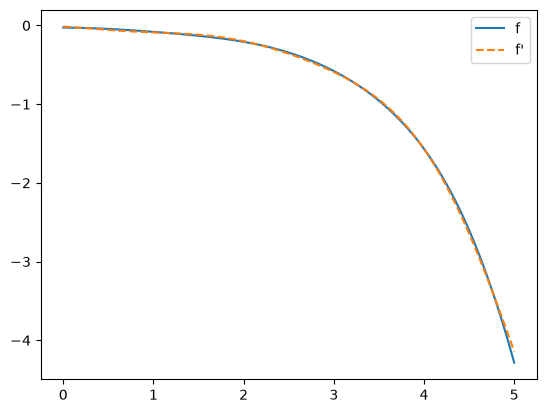

In [11]:
f.cpu()
x = torch.linspace(domain[0], domain[1], 1000).unsqueeze(-1)
with torch.no_grad():
    fx = f(x)
    dfx = f(x, 1)
    d2fx = f(x, 2)
    ffx = f(fx)
f.to(device)

plt.plot(x, fx, label="f")
plt.plot(x, dfx, "--", label="f'")
# plt.plot(x, d2fx, "--", label="f''")
# plt.plot(x, ffx, "--", label="f^2")

plt.legend()
plt.show()	

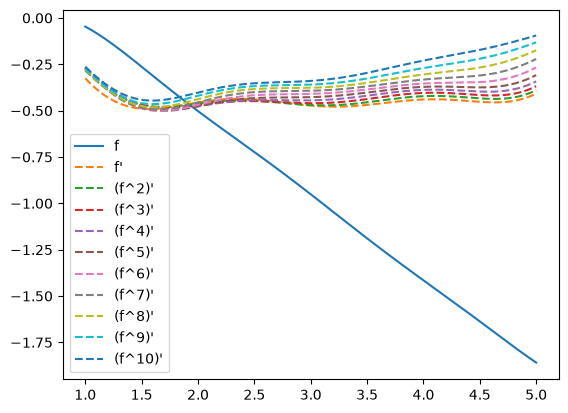

MassEncoder()

In [163]:
f.cpu()
x = torch.linspace(domain[0], domain[1], 1000).unsqueeze(-1)

with torch.no_grad():
    fx, dfx = f.compose(x, 10)

plt.plot(x, fx[0], label="f")
plt.plot(x, dfx[0], "--", label="f'")

for i in range(1, 10):
    plt.plot(x, dfx[i], "--", label=f"(f^{i+1})'")

plt.legend()
plt.show()

f.to(device)